# LogistiX AI — G4 / Prototipo 1
Evaluación 4: predicción de errores de preparación. Objetivo binario, predicción antes del packing.

## 1. Instalar dependencias
Versiones utilizadas en el entrenamiento local. Si Colab solicita reiniciar la sesión, reiniciar y ejecutar desde la siguiente celda.

In [9]:
%pip install -q pandas==2.2.3 numpy==2.4.6 scikit-learn==1.6.1 xgboost==3.4.1 joblib==1.5.3 openpyxl==3.1.5 gradio==6.5.1

## 2. Importación y carga
Pandas lee Excel; NumPy maneja arreglos y umbrales. Scikit-learn divide datos, transforma categorías y evalúa. XGBoost entrena árboles de decisión secuenciales. Joblib guarda el pipeline.

In [10]:
import sys
import pandas as pd
import numpy as np
import sklearn
import xgboost
import joblib
import openpyxl
import gradio as gr
import fastapi
import starlette

print("VERIFICACIÓN DE DEPENDENCIAS")
print("-" * 40)

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Joblib:", joblib.__version__)
print("OpenPyXL:", openpyxl.__version__)
print("Gradio:", gr.__version__)
print("FastAPI:", fastapi.__version__)
print("Starlette:", starlette.__version__)

print("\nImportaciones completadas correctamente.")

with gr.Blocks() as prueba:
    gr.Markdown("# Prueba de LogistiX AI")
    gr.Textbox(label="Prueba de interfaz")

print("Interfaz Gradio creada correctamente.")

import urllib.request

url = "https://raw.githubusercontent.com/acronimoo/logistix-ai-g4/main/LogistiX_G4_Prototipo1/LogistiX_G4/LogistiX.xlsx"

urllib.request.urlretrieve(url, "LogistiX.xlsx")

print("Dataset descargado correctamente.")

from pathlib import Path
import json, hashlib, platform
import pandas as pd
import numpy as np
import joblib
import sklearn, xgboost
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss)
from xgboost import XGBClassifier

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
NUM = ['unidades', 'carga_bodega_pct', 'stock_disponible']
CAT = ['prioridad']
FEATURES = NUM + CAT
TARGET = 'error_preparacion'
SEED = 42



VERIFICACIÓN DE DEPENDENCIAS
----------------------------------------
Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
XGBoost: 3.4.1
Joblib: 1.5.3
OpenPyXL: 3.1.5
Gradio: 6.5.1
FastAPI: 0.141.1
Starlette: 0.52.1

Importaciones completadas correctamente.
Interfaz Gradio creada correctamente.
Dataset descargado correctamente.


In [11]:
from google.colab import files
if not (BASE/'LogistiX.xlsx').exists():
    uploaded = files.upload()
    assert (BASE/'LogistiX.xlsx').exists(), 'Sube el archivo LogistiX.xlsx'
df = pd.read_excel(BASE/'LogistiX.xlsx', sheet_name='LogistiX')
display(df.head())
print('Dimensiones:', df.shape)
print('Nulos:', df.isna().sum())
print('Filas duplicadas:', df.duplicated().sum())
display(df.describe(include='all'))
display(df[TARGET].value_counts().to_frame('pedidos'))

,pedido_id,unidades,distancia_km,carga_bodega_pct,stock_disponible,prioridad,tiempo_picking_min,error_preparacion,entrega_atrasada
0,P00001,23,732,94,117,Alta,12.8,0,0
1,P00002,98,457,86,236,Normal,30.1,0,0
2,P00003,37,415,71,219,Urgente,10.6,1,0
3,P00004,47,529,99,159,Alta,12.5,0,1
4,P00005,113,703,47,158,Urgente,23.7,0,1


Dimensiones: (1200, 9)
Nulos: pedido_id             0
unidades              0
distancia_km          0
carga_bodega_pct      0
stock_disponible      0
prioridad             0
tiempo_picking_min    0
error_preparacion     0
entrega_atrasada      0
dtype: int64
Filas duplicadas: 0


,pedido_id,unidades,distancia_km,carga_bodega_pct,stock_disponible,prioridad,tiempo_picking_min,error_preparacion,entrega_atrasada
count,1200,1200.000000,1200.000000,1200.000000,1200.000000,1200,1200.000000,1200.000000,1200.000000
unique,1200,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN
top,P00001,NaN,NaN,NaN,NaN,Alta,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,408,NaN,NaN,NaN
mean,NaN,59.275000,451.849167,72.845000,122.188333,NaN,16.339250,0.201667,0.473333
std,NaN,34.290269,264.107836,16.519233,71.336938,NaN,4.852997,0.401412,0.499497
min,NaN,1.000000,7.000000,45.000000,0.000000,NaN,2.000000,0.000000,0.000000
25%,NaN,29.000000,217.000000,58.000000,61.000000,NaN,13.075000,0.000000,0.000000
50%,NaN,59.000000,463.000000,73.000000,117.000000,NaN,16.100000,0.000000,0.000000
75%,NaN,87.250000,681.250000,87.000000,183.000000,NaN,19.600000,0.000000,1.000000


,pedidos
error_preparacion,
0,958
1,242


## 3. Preparación y entrenamiento
Excluir pedido_id, entrega_atrasada, distancia_km y tiempo_picking_min. La última variable no se conoce antes de iniciar la preparación. Separar entrenamiento/validación/prueba con estratificación. OneHotEncoder transforma prioridad sin imponer un orden artificial. Pipeline ajusta el preprocesamiento solo en entrenamiento. XGBClassifier aprende con función binary:logistic. F2 favorece la detección de errores; elegir umbral solo con validación.

In [12]:
def load_data(path):
    df = pd.read_excel(path, sheet_name='LogistiX')
    if df[FEATURES + [TARGET]].isna().any().any():
        raise ValueError('El dataset contiene valores nulos en variables seleccionadas.')
    if df.pedido_id.duplicated().any():
        raise ValueError('Se encontraron pedidos repetidos. Revisar antes de entrenar.')
    if set(df[TARGET].unique()) != {0, 1}:
        raise ValueError('La variable objetivo debe contener 0 y 1.')
    return df

def split_data(df):
    X, y = df[FEATURES], df[TARGET]
    X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=.4, random_state=SEED, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=.5, random_state=SEED, stratify=y_rest)
    return X_train, X_val, X_test, y_train, y_val, y_test

def build_model():
    prep = ColumnTransformer([('numericas', 'passthrough', NUM),
                              ('prioridad', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])
    model = XGBClassifier(n_estimators=120, max_depth=3, learning_rate=.05, subsample=.85,
                          colsample_bytree=.9, objective='binary:logistic', eval_metric='logloss',
                          random_state=SEED, n_jobs=2, tree_method='hist')
    return Pipeline([('preprocesamiento', prep), ('modelo', model)])

def evaluate(y, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {'umbral': float(threshold), 'accuracy': float(accuracy_score(y,pred)),
            'precision': float(precision_score(y,pred,zero_division=0)),
            'recall': float(recall_score(y,pred,zero_division=0)),
            'f1': float(f1_score(y,pred,zero_division=0)),
            'f2': float(fbeta_score(y,pred,beta=2,zero_division=0)),
            'roc_auc': float(roc_auc_score(y,prob)), 'average_precision': float(average_precision_score(y,prob)),
            'brier': float(brier_score_loss(y,prob)), 'matriz_confusion': confusion_matrix(y,pred,labels=[0,1]).tolist()}

def run_training(path=BASE/'LogistiX.xlsx', out=BASE/'artefactos'):
    path, out = Path(path), Path(out)
    df = load_data(path)
    X_train,X_val,X_test,y_train,y_val,y_test = split_data(df)
    pipeline = build_model()
    pipeline.fit(X_train,y_train)
    p_val = pipeline.predict_proba(X_val)[:,1]
    # Selección en validación, nunca en test: F2 da más peso a detectar errores.
    candidates = np.arange(.10,.81,.05)
    threshold = float(max(candidates, key=lambda t: (fbeta_score(y_val,p_val>=t,beta=2,zero_division=0),t)))
    threshold = round(threshold,2)
    p_test = pipeline.predict_proba(X_test)[:,1]
    metrics = {'modelo_version':'1.0.0','semilla':SEED,'dataset_sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
               'filas':len(df),'nulos':int(df.isna().sum().sum()),'duplicados_filas':int(df.duplicated().sum()),
               'clases':{str(k):int(v) for k,v in df[TARGET].value_counts().items()},
               'particiones':{'entrenamiento':len(y_train),'validacion':len(y_val),'prueba':len(y_test)},
               'variables':FEATURES,'objetivo':TARGET,'umbral':threshold,
               'validacion_umbral':evaluate(y_val,p_val,threshold),
               'prueba_umbral':evaluate(y_test,p_test,threshold),'prueba_05':evaluate(y_test,p_test,.5),
               'baseline_accuracy':float((y_test==0).mean()),'baseline_recall':0.0,
               'versiones':{'python':platform.python_version(),'sklearn':sklearn.__version__,'xgboost':xgboost.__version__,
                             'pandas':pd.__version__,'numpy':np.__version__}}
    schema = {'variables':FEATURES,'numericas':{c:{'min':int(df[c].min()),'max':int(df[c].max()),'mediana':int(df[c].median())} for c in NUM},
              'prioridades':sorted(df.prioridad.unique().tolist()),'umbral':threshold,'version':'1.0.0'}
    out.mkdir(parents=True,exist_ok=True)
    joblib.dump(pipeline,out/'pipeline.joblib')
    (out/'metricas.json').write_text(json.dumps(metrics,indent=2,ensure_ascii=False),encoding='utf-8')
    (out/'esquema.json').write_text(json.dumps(schema,indent=2,ensure_ascii=False),encoding='utf-8')
    return metrics



In [13]:
metricas = run_training()
print(json.dumps(metricas,indent=2,ensure_ascii=False))

{
  "modelo_version": "1.0.0",
  "semilla": 42,
  "dataset_sha256": "7c0bd37d41d872aaa99ca0a284ab3fa689d961a8c0e674f41d98a2edf08ba718",
  "filas": 1200,
  "nulos": 0,
  "duplicados_filas": 0,
  "clases": {
    "0": 958,
    "1": 242
  },
  "particiones": {
    "entrenamiento": 720,
    "validacion": 240,
    "prueba": 240
  },
  "variables": [
    "unidades",
    "carga_bodega_pct",
    "stock_disponible",
    "prioridad"
  ],
  "objetivo": "error_preparacion",
  "umbral": 0.1,
  "validacion_umbral": {
    "umbral": 0.1,
    "accuracy": 0.3458333333333333,
    "precision": 0.22727272727272727,
    "recall": 0.9183673469387755,
    "f1": 0.3643724696356275,
    "f2": 0.5710659898477157,
    "roc_auc": 0.6243188374826371,
    "average_precision": 0.3178031409195422,
    "brier": 0.15801262158763732,
    "matriz_confusion": [
      [
        38,
        153
      ],
      [
        4,
        45
      ]
    ]
  },
  "prueba_umbral": {
    "umbral": 0.1,
    "accuracy": 0.2875,
    "precis

## 4. Interpretación y verificación
La matriz de confusión compara clases reales con predichas. ROC-AUC cercano a 0,5 indica baja discriminación. Recall mide cuántos errores detecta; precisión indica qué proporción de alertas son errores reales. Una predicción sin alerta no garantiza ausencia de error.

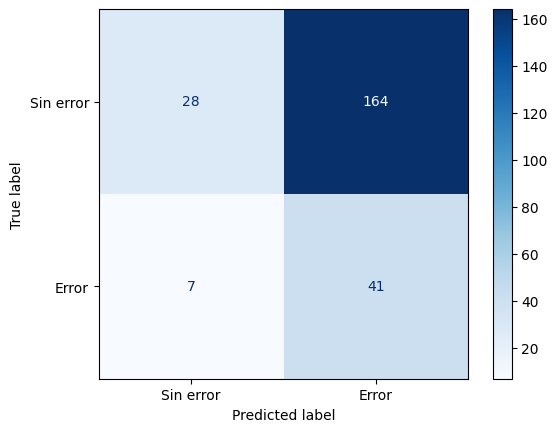

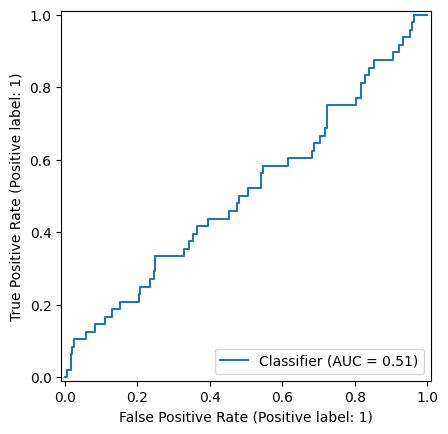

Probabilidad estimada: 11.19%; alerta: True


In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
cm = np.array(metricas['prueba_umbral']['matriz_confusion'])
ConfusionMatrixDisplay(cm,display_labels=['Sin error','Error']).plot(cmap='Blues')
plt.show()
pipeline = joblib.load(BASE/'artefactos'/'pipeline.joblib')
_,_,X_test,_,_,y_test = split_data(df)
RocCurveDisplay.from_predictions(y_test,pipeline.predict_proba(X_test)[:,1])
plt.show()
row = pd.DataFrame([[23,94,117,'Alta']],columns=FEATURES)
p = pipeline.predict_proba(row)[0,1]
print(f'Probabilidad estimada: {p:.2%}; alerta: {p>=metricas["umbral"]}')

## 5. Exportar modelo y preprocesamiento
El archivo pipeline.joblib conserva el modelo entrenado y transformaciones. El JSON de esquema conserva entradas y umbral; el de métricas conserva evidencia y versiones. Cargar solamente archivos joblib propios.

In [15]:
import shutil
shutil.make_archive(str(BASE/'artefactos'),'zip',BASE/'artefactos')
files.download(str(BASE/'artefactos.zip'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Resumen de métricas del modelo

Evaluación del rendimiento del modelo XGBoost sobre el conjunto
de prueba, utilizando el umbral seleccionado mediante F2-Score
en el conjunto de validación.

In [16]:
print("RESULTADOS FINALES DEL MODELO")
print("-" * 40)

m = metricas["prueba_umbral"]

print(f"Umbral: {metricas['umbral']:.2%}")
print(f"Accuracy: {m['accuracy']:.2%}")
print(f"Precision: {m['precision']:.2%}")
print(f"Recall: {m['recall']:.2%}")
print(f"F1-Score: {m['f1']:.2%}")
print(f"F2-Score: {m['f2']:.2%}")
print(f"ROC-AUC: {m['roc_auc']:.4f}")
print(f"Average Precision: {m['average_precision']:.4f}")

print("\nVersiones utilizadas:")
print(metricas["versiones"])

RESULTADOS FINALES DEL MODELO
----------------------------------------
Umbral: 10.00%
Accuracy: 28.75%
Precision: 20.00%
Recall: 85.42%
F1-Score: 32.41%
F2-Score: 51.64%
ROC-AUC: 0.5103
Average Precision: 0.2443

Versiones utilizadas:
{'python': '3.13.18', 'sklearn': '1.6.1', 'xgboost': '3.4.1', 'pandas': '2.2.3', 'numpy': '2.4.6'}


## 7. Implementación de la aplicación web

Se utiliza Gradio como framework de interfaz web para permitir
que los usuarios ingresen las características de un pedido y
obtengan una predicción de riesgo de error de preparación.

La aplicación utiliza el modelo XGBoost y el preprocesamiento
previamente entrenados y almacenados mediante Joblib.

El código fuente de la aplicación se obtiene desde GitHub.

In [17]:
import urllib.request

url_app = "https://raw.githubusercontent.com/acronimoo/logistix-ai-g4/main/LogistiX_G4_Prototipo1/LogistiX_G4/app.py"

urllib.request.urlretrieve(
    url_app,
    str(BASE / "app.py")
)

print("Aplicación descargada correctamente desde GitHub.")
print("Ubicación:", BASE / "app.py")

Aplicación descargada correctamente desde GitHub.
Ubicación: /content/app.py


In [18]:
archivos_necesarios = [
    BASE / "app.py",
    BASE / "artefactos" / "pipeline.joblib",
    BASE / "artefactos" / "metricas.json",
    BASE / "artefactos" / "esquema.json"
]

print("VERIFICACIÓN DE ARCHIVOS")
print("-" * 40)

for archivo in archivos_necesarios:
    if archivo.exists():
        print(f"OK: {archivo.name}")
    else:
        raise FileNotFoundError(
            f"No se encontró {archivo.name}"
        )

print("\nTodos los archivos están disponibles.")

VERIFICACIÓN DE ARCHIVOS
----------------------------------------
OK: app.py
OK: pipeline.joblib
OK: metricas.json
OK: esquema.json

Todos los archivos están disponibles.


In [19]:
import runpy

aplicacion = runpy.run_path(str(BASE / "app.py"))

demo = aplicacion["demo"]
predict_order = aplicacion["predict_order"]

# Predicción mediante la aplicación
probabilidad_app, alerta = predict_order(
    23,
    94,
    117,
    "Alta"
)

# Predicción directamente mediante el modelo
fila = pd.DataFrame(
    [[23, 94, 117, "Alta"]],
    columns=FEATURES
)

probabilidad_modelo = float(
    pipeline.predict_proba(fila)[0, 1]
)

# Comprobar que ambas predicciones coinciden
assert np.isclose(
    probabilidad_app,
    probabilidad_modelo
), "Error: las predicciones no coinciden."

assert alerta == (
    probabilidad_modelo >= metricas["umbral"]
), "Error: el umbral no coincide."

print("PRUEBA DE INTEGRACIÓN EXITOSA")
print("-" * 40)
print(f"Probabilidad aplicación: {probabilidad_app:.2%}")
print(f"Probabilidad modelo: {probabilidad_modelo:.2%}")
print("Alerta:", "Sí" if alerta else "No")
print("La aplicación utiliza correctamente el modelo.")

PRUEBA DE INTEGRACIÓN EXITOSA
----------------------------------------
Probabilidad aplicación: 11.19%
Probabilidad modelo: 11.19%
Alerta: Sí
La aplicación utiliza correctamente el modelo.


## 8. Ejecución de la aplicación web

Se inicia la interfaz Gradio utilizando un enlace público temporal,
permitiendo que los usuarios interactúen con el modelo predictivo
sin necesidad de manipular el código fuente de Google Colab.

In [20]:
import os
import importlib
import traceback
from pathlib import Path

print("=" * 55)
print("DIAGNÓSTICO GENERAL - LOGISTIX AI")
print("=" * 55)

# 1. Verificar dependencias
print("\n1. DEPENDENCIAS")

for nombre in [
    "pandas", "numpy", "sklearn", "xgboost",
    "joblib", "openpyxl", "gradio",
    "fastapi", "starlette"
]:
    try:
        modulo = importlib.import_module(nombre)
        print(f"OK | {nombre}: {modulo.__version__}")
    except Exception as e:
        print(f"ERROR | {nombre}: {e}")

# 2. Verificar archivos
print("\n2. ARCHIVOS DEL PROYECTO")

base = Path(globals().get("BASE", Path.cwd()))

archivos = [
    "LogistiX.xlsx",
    "app.py",
    "artefactos/pipeline.joblib",
    "artefactos/metricas.json",
    "artefactos/esquema.json"
]

for archivo in archivos:
    ruta = base / archivo

    if ruta.is_file():
        print(f"OK | {archivo}")
    else:
        print(f"ERROR | No existe {archivo}")

# 3. Verificar variables
print("\n3. VARIABLES DEL NOTEBOOK")

for variable in [
    "BASE", "df", "FEATURES", "TARGET",
    "metricas", "pipeline", "demo", "predict_order"
]:
    if variable in globals():
        print(f"OK | {variable}")
    else:
        print(f"ERROR | {variable} no definida")

# 4. Comprobar el modelo guardado
print("\n4. PRUEBA DEL MODELO")

try:
    import joblib
    import pandas as pd

    modelo = joblib.load(
        base / "artefactos/pipeline.joblib"
    )

    datos = pd.DataFrame(
        [[23, 94, 117, "Alta"]],
        columns=[
            "unidades",
            "carga_bodega_pct",
            "stock_disponible",
            "prioridad"
        ]
    )

    probabilidad = modelo.predict_proba(datos)[0, 1]

    print("OK | Modelo cargado correctamente")
    print(f"Probabilidad: {probabilidad:.2%}")

except Exception:
    traceback.print_exc()

# 5. Comprobar la aplicación
print("\n5. PRUEBA DE LA APLICACIÓN")

try:
    import runpy

    app_diagnostico = runpy.run_path(
        str(base / "app.py")
    )

    prob, alerta = app_diagnostico["predict_order"](
        23, 94, 117, "Alta"
    )

    print("OK | Aplicación cargada correctamente")
    print(f"Probabilidad: {prob:.2%}")
    print("Alerta:", alerta)

except Exception:
    traceback.print_exc()

print("\nFIN DEL DIAGNÓSTICO")

DIAGNÓSTICO GENERAL - LOGISTIX AI

1. DEPENDENCIAS
OK | pandas: 2.2.3
OK | numpy: 2.4.6
OK | sklearn: 1.6.1
OK | xgboost: 3.4.1
OK | joblib: 1.5.3
OK | openpyxl: 3.1.5
OK | gradio: 6.5.1
OK | fastapi: 0.141.1
OK | starlette: 0.52.1

2. ARCHIVOS DEL PROYECTO
OK | LogistiX.xlsx
OK | app.py
OK | artefactos/pipeline.joblib
OK | artefactos/metricas.json
OK | artefactos/esquema.json

3. VARIABLES DEL NOTEBOOK
OK | BASE
OK | df
OK | FEATURES
OK | TARGET
OK | metricas
OK | pipeline
OK | demo
OK | predict_order

4. PRUEBA DEL MODELO
OK | Modelo cargado correctamente
Probabilidad: 11.19%

5. PRUEBA DE LA APLICACIÓN
OK | Aplicación cargada correctamente
Probabilidad: 11.19%
Alerta: True

FIN DEL DIAGNÓSTICO


In [21]:
demo.launch(
    share=True,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://84c7a53aed06cb12cf.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/queueing.py", line 766, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/route_utils.py", line 355, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<11 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2148, in process_api
    inputs = await self.preprocess_data(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^
        block_fn, inputs, state, explicit_call
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 1790, in preprocess_data
    processed_value = block.preprocess(inputs_cached)
  File "/usr/local/lib/python3.13/dist-packages/gradio/components/num

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://84c7a53aed06cb12cf.gradio.live
